In [1]:
!pip install pdfplumber spacy pyvis networkx requests -q
!python -m spacy download en_core_web_sm -q

import spacy, pdfplumber, networkx as nx, re, os, time, requests
from collections import Counter
from pyvis.network import Network
import matplotlib.pyplot as plt

nlp = spacy.load("en_core_web_sm")
print("Setup done")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 547.5 kB/s eta 0:00:00 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.5/66.5 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 20.7 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 756.0/756.0 kB 34.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 48.0 MB/s eta 0:00:0000:0100:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.7/3.7 MB 91.4 MB/s eta 0:00:00:00:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
gradio 5.50.0 requires pillow<12.0,>=8.0, but you have pillow 12.3.0 which is incompatible.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 5

In [2]:
paper_ids = {
    "1706.03762": "Attention Is All You Need",
    "2005.14165": "GPT-3 Language Models are Few-Shot Learners",
    "1412.6572": "Explaining and Harnessing Adversarial Examples (FGSM)",
    "1710.08864": "One Pixel Attack for Fooling Deep Neural Networks",
    "1706.06083": "Towards Deep Learning Models Resistant to Adversarial Attacks (PGD)",
    "1810.04805": "BERT: Pre-training of Deep Bidirectional Transformers"
}

os.makedirs("papers", exist_ok=True)
papers = {}

for pid, title in paper_ids.items():
    pdf_path = f"papers/{pid}.pdf"
    url = f"https://arxiv.org/pdf/{pid}.pdf"
    try:
        r = requests.get(url, headers={'User-Agent': 'Mozilla/5.0'}, timeout=20)
        with open(pdf_path, "wb") as f:
            f.write(r.content)

        text = ""
        with pdfplumber.open(pdf_path) as pdf:
            for page in pdf.pages:
                t = page.extract_text()
                if t:
                    text += t + " "
        papers[title] = text
        print(f"{title}: extracted {len(text)} characters")
    except Exception as e:
        print(f"{title}: FAILED - {e}")
    time.sleep(2)

print(f"\nTotal papers loaded: {len(papers)}")

Attention Is All You Need: extracted 35526 characters
GPT-3 Language Models are Few-Shot Learners: extracted 213836 characters
Explaining and Harnessing Adversarial Examples (FGSM): extracted 42257 characters
One Pixel Attack for Fooling Deep Neural Networks: extracted 59538 characters
Towards Deep Learning Models Resistant to Adversarial Attacks (PGD): extracted 63717 characters
BERT: Pre-training of Deep Bidirectional Transformers: extracted 61505 characters

Total papers loaded: 6


In [3]:
def clean(text):
    text = re.sub(r'-\n', '', text)
    text = re.sub(r'\s+', ' ', text)
    return text

paper_sents = {}
for name, text in papers.items():
    doc = nlp(clean(text))
    paper_sents[name] = [s.text.strip() for s in doc.sents if len(s.text.split()) > 4]
    print(f"{name}: {len(paper_sents[name])} sentences")

Attention Is All You Need: 106 sentences
GPT-3 Language Models are Few-Shot Learners: 657 sentences
Explaining and Harnessing Adversarial Examples (FGSM): 170 sentences
One Pixel Attack for Fooling Deep Neural Networks: 387 sentences
Towards Deep Learning Models Resistant to Adversarial Attacks (PGD): 221 sentences
BERT: Pre-training of Deep Bidirectional Transformers: 396 sentences


In [4]:
STOP_GENERIC = {"this paper", "this section", "this work", "the paper", "this study", "we", "it", "they"}

def get_concepts(sent_doc):
    chunks = []
    for chunk in sent_doc.noun_chunks:
        text = chunk.text.lower().strip()
        text = re.sub(r'^(the|a|an|this|these|those|our|its)\s+', '', text)
        if 2 <= len(text) <= 40 and text not in STOP_GENERIC and not text.isdigit():
            chunks.append(text)
    return chunks

edges = []
all_concepts = Counter()

for name, sents in paper_sents.items():
    for sent in sents:
        sdoc = nlp(sent)
        concepts = get_concepts(sdoc)
        for c in concepts:
            all_concepts[c] += 1
        for token in sdoc:
            if token.pos_ == "VERB":
                subj = [w for w in token.lefts if w.dep_ in ("nsubj", "nsubjpass")]
                obj = [w for w in token.rights if w.dep_ in ("dobj", "attr", "prep", "pobj")]
                if subj and obj:
                    s_text = subj[0].text.lower()
                    o_text = obj[0].text.lower()
                    edges.append((s_text, o_text, token.lemma_, name))
    print(f"Processed: {name}")

print(f"\nTotal unique candidate concepts: {len(all_concepts)}")
print(f"Total candidate relation edges: {len(edges)}")

Processed: Attention Is All You Need
Processed: GPT-3 Language Models are Few-Shot Learners
Processed: Explaining and Harnessing Adversarial Examples (FGSM)
Processed: One Pixel Attack for Fooling Deep Neural Networks
Processed: Towards Deep Learning Models Resistant to Adversarial Attacks (PGD)
Processed: BERT: Pre-training of Deep Bidirectional Transformers

Total unique candidate concepts: 5194
Total candidate relation edges: 913


In [5]:
TOP_N = 60
top_concepts = set(c for c, _ in all_concepts.most_common(TOP_N))

filtered_edges = [(s, o, v, p) for (s, o, v, p) in edges if s in top_concepts and o in top_concepts and s != o]
print(f"Edges after filtering to top {TOP_N} concepts: {len(filtered_edges)}")

def normalize(c):
    return " ".join(t.lemma_ for t in nlp(c))

norm_map = {c: normalize(c) for c in top_concepts}

def canon(c):
    return norm_map.get(c, c)

print("\nTop 20 concepts by raw frequency:")
for c, count in all_concepts.most_common(20):
    print(f"{c}: {count}")

Edges after filtering to top 60 concepts: 29

Top 20 concepts by raw frequency:
which: 80
that: 80
you: 39
this: 38
he: 38
adversarial examples: 32
bert: 30
model: 26
them: 25
example: 24
case: 23
number: 23
proceedings: 22
acc: 22
al: 21
results: 20
figure: 20
target completion: 20
table: 19
training: 18


In [6]:
NOISE = {"which", "that", "you", "this", "he", "she", "they", "them", "it", "we", "i",
         "case", "number", "proceedings", "acc", "al", "results", "figure", "table",
         "example", "examples", "section", "et al", "fig", "eq", "equation"}

def get_concepts(sent_doc):
    chunks = []
    for chunk in sent_doc.noun_chunks:
        if chunk.root.pos_ not in ("NOUN", "PROPN"):
            continue
        text = chunk.text.lower().strip()
        text = re.sub(r'^(the|a|an|this|these|those|our|its)\s+', '', text)
        if text in NOISE or len(text) < 3 or len(text) > 40 or text.isdigit():
            continue
        if all(t.is_stop for t in chunk):
            continue
        chunks.append(text)
    return chunks

def good_token(tok):
    return tok.pos_ in ("NOUN", "PROPN") and tok.lemma_.lower() not in NOISE and not tok.is_stop

edges = []
all_concepts = Counter()

for name, sents in paper_sents.items():
    for sent in sents:
        sdoc = nlp(sent)
        concepts = get_concepts(sdoc)
        for c in concepts:
            all_concepts[c] += 1
        for token in sdoc:
            if token.pos_ == "VERB":
                subj = [w for w in token.lefts if w.dep_ in ("nsubj", "nsubjpass") and good_token(w)]
                obj = [w for w in token.rights if w.dep_ in ("dobj", "attr", "prep", "pobj") and good_token(w)]
                if subj and obj:
                    edges.append((subj[0].text.lower(), obj[0].text.lower(), token.lemma_, name))
    print(f"Processed: {name}")

print(f"\nTotal unique candidate concepts: {len(all_concepts)}")
print(f"Total candidate relation edges: {len(edges)}")
print("\nTop 25 concepts by frequency:")
for c, count in all_concepts.most_common(25):
    print(f"{c}: {count}")

Processed: Attention Is All You Need
Processed: GPT-3 Language Models are Few-Shot Learners
Processed: Explaining and Harnessing Adversarial Examples (FGSM)
Processed: One Pixel Attack for Fooling Deep Neural Networks
Processed: Towards Deep Learning Models Resistant to Adversarial Attacks (PGD)
Processed: BERT: Pre-training of Deep Bidirectional Transformers

Total unique candidate concepts: 5073
Total candidate relation edges: 263

Top 25 concepts by frequency:
adversarial examples: 32
bert: 30
model: 26
target completion: 20
training: 18
incorrect answer: 18
images: 17
network: 17
word: 16
attack: 14
pgd: 14
time: 13
fact: 12
networks: 12
robustness: 12
answer: 11
imagenet: 11
natural images: 11
models: 10
work: 10
input: 10
performance: 10
gpt-3: 10
sentence: 10
context: 10


In [7]:
TOP_N = 60
top_concepts = set(c for c, _ in all_concepts.most_common(TOP_N))

filtered_edges = [(s, o, v, p) for (s, o, v, p) in edges if s in top_concepts and o in top_concepts and s != o]
print(f"Edges after filtering to top {TOP_N} concepts: {len(filtered_edges)}")

def normalize(c):
    return " ".join(t.lemma_ for t in nlp(c))

norm_map = {c: normalize(c) for c in top_concepts}
def canon(c):
    return norm_map.get(c, c)

G = nx.DiGraph()
edge_weight = Counter()
edge_papers = {}
edge_verbs = {}

for s, o, v, p in filtered_edges:
    cs, co = canon(s), canon(o)
    if cs == co:
        continue
    key = (cs, co)
    edge_weight[key] += 1
    edge_papers.setdefault(key, set()).add(p)
    edge_verbs.setdefault(key, Counter())[v] += 1

for (s, o), w in edge_weight.items():
    top_verb = edge_verbs[(s, o)].most_common(1)[0][0]
    G.add_edge(s, o, weight=w, verb=top_verb, papers=list(edge_papers[(s, o)]))

print(f"Final graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")
print("\nSample edges (source -> verb -> target [papers]):")
for u, v, d in list(G.edges(data=True))[:15]:
    print(f"{u} --{d['verb']}--> {v}  [{', '.join(d['papers'])}]")

Edges after filtering to top 60 concepts: 10
Final graph: 13 nodes, 10 edges

Sample edges (source -> verb -> target [papers]):
experiment --show--> model  [Attention Is All You Need]
layer --have--> model  [Attention Is All You Need]
gpt-3 --approach--> performance  [GPT-3 Language Models are Few-Shot Learners]
gpt-3 --outperform--> work  [GPT-3 Language Models are Few-Shot Learners]
work --base--> model  [GPT-3 Language Models are Few-Shot Learners]
task --improve--> performance  [GPT-3 Language Models are Few-Shot Learners]
perturbation --become--> way  [One Pixel Attack for Fooling Deep Neural Networks]
attack --break--> confidence  [One Pixel Attack for Fooling Deep Neural Networks]
network --have--> robustness  [One Pixel Attack for Fooling Deep Neural Networks]
network --have--> performance  [Towards Deep Learning Models Resistant to Adversarial Attacks (PGD)]


In [8]:
TOP_N = 80
top_concepts = set(c for c, _ in all_concepts.most_common(TOP_N))

def normalize(c):
    return " ".join(t.lemma_ for t in nlp(c))

norm_map = {c: normalize(c) for c in top_concepts}
def canon(c):
    return norm_map.get(c, c)

edge_weight = Counter()
edge_papers = {}
edge_verbs = {}

# Layer 1: SVO relation edges (precise, verb-labeled)
for s, o, v, p in edges:
    if s not in top_concepts or o not in top_concepts:
        continue
    cs, co = canon(s), canon(o)
    if cs == co:
        continue
    key = tuple(sorted([cs, co]))
    edge_weight[key] += 2  # weight SVO higher, it's more precise
    edge_papers.setdefault(key, set()).add(p)
    edge_verbs.setdefault(key, Counter())[v] += 2

# Layer 2: co-occurrence edges (sentence-level relatedness)
for name, sents in paper_sents.items():
    for sent in sents:
        sdoc = nlp(sent)
        present = set()
        for chunk in sdoc.noun_chunks:
            text = re.sub(r'^(the|a|an|this|these|those|our|its)\s+', '', chunk.text.lower().strip())
            if text in top_concepts:
                present.add(canon(text))
        present = list(present)
        for i in range(len(present)):
            for j in range(i+1, len(present)):
                key = tuple(sorted([present[i], present[j]]))
                edge_weight[key] += 1
                edge_papers.setdefault(key, set()).add(name)
                edge_verbs.setdefault(key, Counter())["relates to"] += 1

G = nx.Graph()
for key, w in edge_weight.items():
    if w < 2:  # drop one-off noise
        continue
    s, o = key
    top_verb = edge_verbs[key].most_common(1)[0][0]
    G.add_edge(s, o, weight=w, verb=top_verb, papers=list(edge_papers[key]))

print(f"Final graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")
papers_covered = set()
for _, _, d in G.edges(data=True):
    papers_covered.update(d["papers"])
print(f"Papers represented: {papers_covered}")
print("\nTop 15 edges by weight:")
for u, v, d in sorted(G.edges(data=True), key=lambda x: -x[2]['weight'])[:15]:
    print(f"{u} --{d['verb']}--> {v}  (weight={d['weight']}, papers={d['papers']})")

Final graph: 39 nodes, 33 edges
Papers represented: {'Attention Is All You Need', 'BERT: Pre-training of Deep Bidirectional Transformers', 'GPT-3 Language Models are Few-Shot Learners', 'Towards Deep Learning Models Resistant to Adversarial Attacks (PGD)', 'One Pixel Attack for Fooling Deep Neural Networks', 'Explaining and Harnessing Adversarial Examples (FGSM)'}

Top 15 edges by weight:
sentence --relates to--> word  (weight=5, papers=['GPT-3 Language Models are Few-Shot Learners'])
israel --relates to--> rabin  (weight=5, papers=['GPT-3 Language Models are Few-Shot Learners'])
answer --relates to--> target completion  (weight=5, papers=['GPT-3 Language Models are Few-Shot Learners'])
experiment --show--> model  (weight=4, papers=['Attention Is All You Need', 'BERT: Pre-training of Deep Bidirectional Transformers'])
train --relates to--> bert  (weight=4, papers=['BERT: Pre-training of Deep Bidirectional Transformers'])
image --relates to--> imagenet  (weight=4, papers=['One Pixel Att

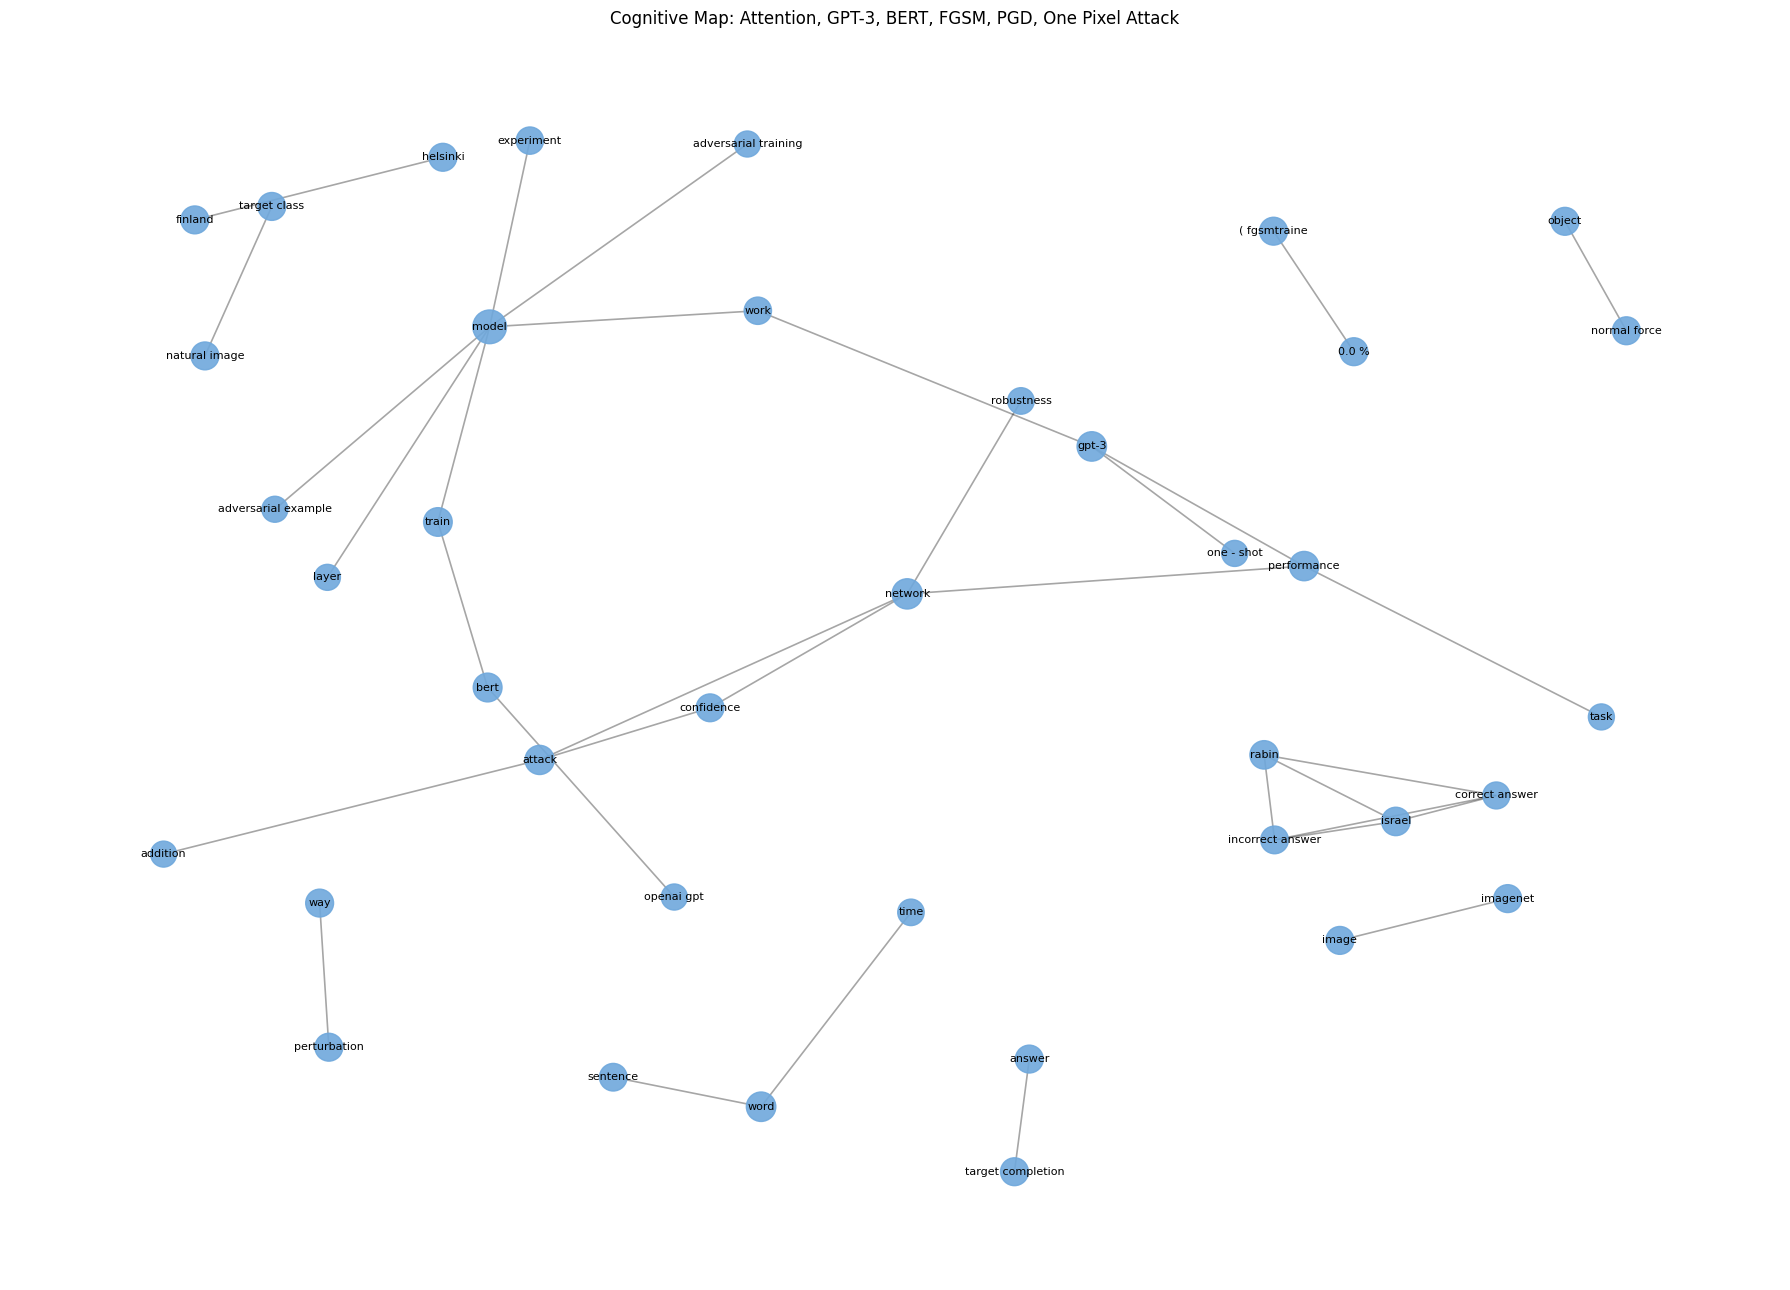

Top 15 concepts by importance (PageRank):
model: 0.0722
network: 0.0435
word: 0.0374
gpt-3: 0.0373
performance: 0.0364
attack: 0.0354
bert: 0.0326
train: 0.0311
israel: 0.0296
rabin: 0.0296
perturbation: 0.0256
way: 0.0256
finland: 0.0256
helsinki: 0.0256
answer: 0.0256


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
pagerank = nx.pagerank(G, weight="weight")
nx.set_node_attributes(G, pagerank, "importance")

plt.figure(figsize=(18, 13))
pos = nx.spring_layout(G, k=0.7, seed=42, weight="weight")
sizes = [4000 * pagerank[n] + 300 for n in G.nodes()]
nx.draw_networkx_nodes(G, pos, node_size=sizes, node_color="#6fa8dc", alpha=0.9)
nx.draw_networkx_edges(G, pos, alpha=0.35, width=1.2)
nx.draw_networkx_labels(G, pos, font_size=8)
plt.axis("off")
plt.title("Cognitive Map: Attention, GPT-3, BERT, FGSM, PGD, One Pixel Attack")
plt.tight_layout()
plt.savefig("cognitive_map_static.png", dpi=200)
plt.show()

net = Network(height="800px", width="100%", notebook=False, bgcolor="#ffffff")
for n in G.nodes():
    net.add_node(n, label=n, value=pagerank[n]*1000+5, title=f"importance: {pagerank[n]:.4f}")
for u, v, d in G.edges(data=True):
    net.add_edge(u, v, value=d["weight"], title=f"{d['verb']} (in: {', '.join(d['papers'])})")
net.show_buttons(filter_=['physics'])
net.write_html("cognitive_map_interactive.html")

print("Top 15 concepts by importance (PageRank):")
for c, score in sorted(pagerank.items(), key=lambda x: -x[1])[:15]:
    print(f"{c}: {score:.4f}")

from google.colab import files
files.download("cognitive_map_static.png")
files.download("cognitive_map_interactive.html")

In [10]:

from google.colab import files
import time
time.sleep(1)
files.download("cognitive_map_static.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
import os
print(os.listdir("."))

['lib', 'cognitive_map_static.png', 'papers', 'cognitive_map_interactive.html', '.virtual_documents']
